# Tarea 2 · Parte 1 — Corpus y extracción (OCR + ASR)

**Pregunta guía:** ¿Pueden convertirse documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable?

| | |
|---|---|
| **Fecha de extracción** | 2026-10-25 (descarga con `descargar_datos.py`, API de Wikimedia y OpenSLR) |
| **Entorno** | Python 3.12 en Windows 11, solo CPU (AMD Ryzen 7 8845HS, 14 GB RAM). Entorno `tarea_2/.venv` creado con `uv` con los paquetes de los grupos `docai` y `audio` del curso (`paddleocr`, `paddlepaddle`, `faster-whisper`, `pyannote-audio`, `transformers`, `jiwer`) |
| **OCR** | PaddleOCR **3.7.0** sobre PaddlePaddle 3.3.1 (pipeline general de OCR con `lang="es"` → detector `PP-OCRv6_medium_det` + reconocedor multilingüe `PP-OCRv6_medium_rec`; `enable_mkldnn=False` porque la aceleración oneDNN falla con PaddlePaddle 3.3.1 en Windows) |
| **ASR** | faster-whisper **1.2.1** con **Whisper large-v3-turbo** (`mobiuslabsgmbh/faster-whisper-large-v3-turbo`, CTranslate2 int8 en CPU), VAD Silero activado, `language="es"`, `beam_size=5` |
| **Diarización** | Huellas de voz WeSpeaker ResNet34 (`pyannote/wespeaker-voxceleb-resnet34-LM`, pyannote.audio 4.0.7) + clustering jerárquico coseno (`voz.diarizar`, umbral 0,7) |
| **Seudonimización** | NER `mrm8488/bert-spanish-cased-finetuned-ner` para proponer candidatos + revisión humana + `voz.seudonimizar` (coincidencia difusa) + regex de DNI, teléfono y correo |

### Fuentes y licencias

| Corpus | Fuente | Licencia | Archivos |
|---|---|---|---|
| Documentos impresos | Escaneos de Wikisource: *Tradiciones peruanas* (Ricardo Palma, 1893), *Historia General del Perú* (Inca Garcilaso, ed. 1800), Decreto Ley 17716 de Reforma Agraria (1969) | Dominio público | 8 |
| Documentos fotografiados | Fotos de placas y de un documento enmarcado en Lima, Wikimedia Commons (autores: AlejandroFC, Omar Vega Ramos, TheLimean, Dtarazona, Ministerio de Defensa del Perú) | CC BY-SA 4.0 / CC BY-SA 3.0 / CC BY 2.0 / dominio público | 8 |
| Manuscritos | *Nueva corónica y buen gobierno* de Guaman Poma (1615), Acta de la Independencia del Perú (1821), Capitulación de Ayacucho (1824), Wikimedia Commons | Dominio público (facsímil fotografiado: CC BY-SA 3.0, Murillo Perú) | 9 |
| Entrevistas | Wikimedia Commons, Lima 2022 (JorgeFlores-pe / Wikimedia Perú, QM Keen, Gianpier Yair Venegas Ambia, Ariana Lucero De La Cruz Guerrero) | CC BY-SA 4.0 | 8 |
| Lectura en español peruano | OpenSLR 73, *Crowdsourced high-quality Peruvian Spanish speech data set* (Google; Guevara-Rukoz et al., 2020) | CC BY-SA 4.0 | 15 |

El detalle por archivo (URL, autor, licencia y cómo recuperarlo) está en `datos/fuentes.csv`. Los archivos originales quedan en `datos/raw/` y **no se suben a GitHub** (`.gitignore`); `descargar_datos.py` los vuelve a bajar.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import herramientas as H  # importa torch antes que paddle (en Windows, al revés falla la carga de DLL)
import voz

import hashlib
import json
import shutil
from collections import Counter
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import soundfile as sf

pio.renderers.default = "plotly_mimetype+png"  # interactivo en Jupyter y PNG visible en GitHub
pd.set_option("display.max_colwidth", 110)
BASE, RAW = H.BASE, H.RAW
for p in ["paddleocr", "paddlepaddle", "faster-whisper", "ctranslate2", "pyannote.audio", "transformers", "torch", "jiwer", "plotly"]:
    print(f"{p:15s} {version(p)}")

paddleocr       3.7.0
paddlepaddle    3.3.1
faster-whisper  1.2.1
ctranslate2     4.8.4
pyannote.audio  4.0.7
transformers    5.20.2
torch           2.14.1+cpu
jiwer           4.0.0
plotly          7.1.0


## 1. Inventario de fuentes
`descargar_datos.py` dejó un inventario con la fuente, el autor y la licencia de cada archivo.

In [2]:
inv = pd.read_csv(RAW / "inventario_fuentes.csv")
print(inv.groupby(["modalidad", "licencia"]).size().to_string())
docs = inv[inv["modalidad"] == "documento"].copy()
clips = inv[inv["modalidad"] == "audio"].copy()
print(f"\n{len(docs)} documentos y {len(clips)} clips de audio descargados")

modalidad  licencia                         
audio      CC BY-SA 4.0                         23
documento  CC BY 2.0                             1
           CC BY-SA 3.0                          2
           CC BY-SA 4.0                          5
           Dominio público (texto y escaneo)     8
           Public domain                        10

26 documentos y 23 clips de audio descargados


## 2. Limpieza: duplicados, documentos ilegibles y audios sin voz

**Candidatos revisados y descartados antes de la descarga.** Al armar el corpus se revisaron visualmente más imágenes de Commons de las que se usaron. Estas se descartaron:

In [3]:
descartes_previos = pd.DataFrame([
    ("Capitulación de Ayacucho1.jpg", "No es un documento: es una pintura (D. Hernández) de la firma de la capitulación"),
    ("Firma el actual del Perú.jpg", "Grabado de la firma del acta, sin texto legible"),
    ("Pasaporte de Arequipa.jpg", "Ilegible: 227 × 352 px, el texto no se distingue"),
    ("Placa Calle Capon.jpg", "Casi sin texto (solo «Calle Capón»)"),
    ("Acta de Creación de los Símbolos para el Distrito de Mache - Perù.jpg", "Datos personales: nombres y firmas de autoridades locales vivas"),
    ("Carta de agradecimiento ... Segundo Ciro Gallardo Gallo ... .jpg", "Datos personales: carta dirigida a una persona privada"),
    ("Placa de alcaldes de San Juan de Lurigancho 01/02.jpg", "Datos personales: lista de nombres de alcaldes recientes; aporta solo nombres"),
], columns=["archivo_commons", "motivo_descarte"])
descartes_previos

,archivo_commons,motivo_descarte
0,Capitulación de Ayacucho1.jpg,No es un documento: es una pintura (D. Hernández) de la firma de la capitulación
1,Firma el actual del Perú.jpg,"Grabado de la firma del acta, sin texto legible"
2,Pasaporte de Arequipa.jpg,"Ilegible: 227 × 352 px, el texto no se distingue"
3,Placa Calle Capon.jpg,Casi sin texto (solo «Calle Capón»)
4,Acta de Creación de los Símbolos para el Distrito de Mache - Perù.jpg,Datos personales: nombres y firmas de autoridades locales vivas
5,Carta de agradecimiento ... Segundo Ciro Gallardo Gallo ... .jpg,Datos personales: carta dirigida a una persona privada
6,Placa de alcaldes de San Juan de Lurigancho 01/02.jpg,Datos personales: lista de nombres de alcaldes recientes; aporta solo nombres


**Duplicados por hash.** Se calcula el SHA-1 de cada archivo descargado; dos archivos con el mismo hash son la misma imagen o el mismo audio.

In [4]:
def sha1(ruta):
    return hashlib.sha1(Path(ruta).read_bytes()).hexdigest()

docs["sha1"] = [sha1(BASE / a) for a in docs["archivo"]]
clips["sha1"] = [sha1(BASE / a) for a in clips["archivo_original"]]
dup_docs = docs[docs.duplicated("sha1", keep="first")]
dup_clips = clips[clips.duplicated("sha1", keep="first")]
print(f"Documentos duplicados por hash: {len(dup_docs)} | clips duplicados por hash: {len(dup_clips)}")
docs = docs.drop(dup_docs.index)
clips = clips.drop(dup_clips.index)

Documentos duplicados por hash: 0 | clips duplicados por hash: 0


**Audios sin voz.** Antes de transcribir, el detector de voz Silero (`voz.tramos_de_voz`) mide qué fracción de cada clip tiene voz. Regla fijada de antemano: se descarta un clip con menos de 20 % de voz. Además, todo el audio se convierte a WAV mono de 16 kHz (`datos/raw/audio/clip_XXX.wav`), el formato que esperan los modelos.

In [5]:
filas = []
for r in clips.itertuples():
    audio = voz.cargar_audio(BASE / r.archivo_original)
    wav = RAW / "audio" / f"{r.id}.wav"
    if not wav.exists():
        sf.write(wav, audio, voz.SR)
    tramos = voz.tramos_de_voz(audio)
    dur = len(audio) / voz.SR
    filas.append({"id": r.id, "duracion_seg": round(dur, 1), "seg_voz": round(sum(b - a for a, b in tramos), 1),
                  "fraccion_voz": round(sum(b - a for a, b in tramos) / dur, 2)})
voz_df = pd.DataFrame(filas)
clips = clips.merge(voz_df, on="id")
clips["archivo_audio"] = [f"datos/raw/audio/{i}.wav" for i in clips["id"]]
sin_voz = clips[clips["fraccion_voz"] < 0.2]
print(f"Clips sin voz (<20 % de voz): {len(sin_voz)}")
clips = clips.drop(sin_voz.index)
print(f"Audio después de la limpieza: {len(clips)} clips, {clips['duracion_seg'].sum() / 60:.1f} min "
      f"({clips['seg_voz'].sum() / 60:.1f} min con voz)")
clips[["id", "fuente", "duracion_seg", "fraccion_voz"]].sort_values("fraccion_voz").head(5)

Clips sin voz (<20 % de voz): 0
Audio después de la limpieza: 23 clips, 37.8 min (26.0 min con voz)


,id,fuente,duracion_seg,fraccion_voz
19,clip_020,OpenSLR 73,75.0,0.42
18,clip_019,OpenSLR 73,70.3,0.43
14,clip_015,OpenSLR 73,110.7,0.45
9,clip_010,OpenSLR 73,89.3,0.45
22,clip_023,OpenSLR 73,109.4,0.46


## 3. OCR con PaddleOCR (Sesión 10)

**Parámetros:** `PaddleOCR(lang="es")` con la configuración de fábrica (PP-OCRv6 medium): sin clasificador de orientación de página, sin corrección de deformación y sin clasificador de orientación de línea (esa variante con preprocesamiento se compara en la Parte 2). Las imágenes entran tal como se descargaron (JPEG, lado mayor ≤ 1920 px; páginas de libro a 1280 px de ancho), sin binarizar ni recortar.

**Respaldo crudo:** por cada documento se guarda en `datos/raw/documentos/paddle/<id>/` el JSON de PaddleOCR (cajas, textos y confianzas), la imagen con las cajas dibujadas y **un recorte por línea detectada** (`recortes/linea_XXX.png`). Los resultados se guardan en caché (`datos/raw/cache/`) para no repetir la inferencia al re-ejecutar el notebook.

In [6]:
def ocr_doc(r):
    return H.ocr_paddle(BASE / r.archivo, "paddle_base", salida=RAW / "documentos" / "paddle" / r.id)

ocr = {r.id: H.en_cache(f"ocr_paddle_base_{r.id}", ocr_doc, r) for r in docs.itertuples()}
docs["texto_ocr_crudo"] = docs["id"].map(lambda i: ocr[i]["texto"])
docs["n_lineas_ocr"] = docs["id"].map(lambda i: ocr[i]["n_lineas"])
docs["confianza_ocr"] = docs["id"].map(lambda i: ocr[i]["confianza_media"])
docs["segundos_ocr"] = docs["id"].map(lambda i: ocr[i]["segundos"])
n_recortes = sum(len(list((RAW / "documentos" / "paddle" / i / "recortes").glob("*.png"))) for i in docs["id"])
print(f"OCR listo: {len(docs)} documentos, {docs['n_lineas_ocr'].sum()} líneas ({n_recortes} recortes guardados), "
      f"{docs['segundos_ocr'].sum():.0f} s de CPU en total")
docs.groupby("tipo")[["n_lineas_ocr", "confianza_ocr", "segundos_ocr"]].mean().round(2)

OCR listo: 26 documentos, 624 líneas (624 recortes guardados), 955 s de CPU en total


,n_lineas_ocr,confianza_ocr,segundos_ocr
tipo,,,
foto,16.25,0.91,41.90
impreso,40.12,0.98,48.63
manuscrito,17.30,0.73,23.08


**Documentos ilegibles.** Regla fijada de antemano: un documento se descarta si el OCR no encuentra ninguna línea con confianza ≥ 0,5 **y** la revisión visual confirma que el texto no se puede leer.

In [7]:
sin_texto = docs[(docs["n_lineas_ocr"] == 0) | (docs["confianza_ocr"].fillna(0) < 0.5)]
print(f"Documentos sin texto reconocible por el OCR: {len(sin_texto)}")
display(sin_texto[["id", "tipo", "descripcion", "n_lineas_ocr", "confianza_ocr"]])
docs = docs.drop(sin_texto.index)
print(f"Corpus final: {len(docs)} documentos {docs['tipo'].value_counts().to_dict()}")

Documentos sin texto reconocible por el OCR: 1


,id,tipo,descripcion,n_lineas_ocr,confianza_ocr
24,doc_025,manuscrito,"Capitulación de Ayacucho (1824), página manuscrita",0,NaN


Corpus final: 25 documentos {'manuscrito': 9, 'impreso': 8, 'foto': 8}


**Descarte:** `doc_025` (página de la Capitulación de Ayacucho) no tiene ninguna línea detectada y, al revisarla, se confirma que a 362 × 550 px los trazos no se distinguen: se descarta como **ilegible** y se reemplaza por `doc_026` (Guaman Poma, el *khipucamayoc*, 864 × 1296 px), que `descargar_datos.py` baja como reemplazo. El corpus queda en **25 documentos: 8 impresos, 8 fotos y 9 manuscritos**.

Los demás manuscritos tienen la confianza más baja, pero **no son ilegibles para una persona** (Guaman Poma y el Acta se leen y existen transcripciones), así que se mantienen: son justamente el caso difícil que pide la tarea.

## 4. ASR con faster-whisper + VAD y diarización (Sesión 13)

Se usa `voz.Transcriptor("faster-whisper")` del curso: Whisper large-v3-turbo en CTranslate2 int8, **`vad_filter=True`** (Silero VAD: no se le manda silencio al modelo, lo que evita las alucinaciones típicas de Whisper en pausas, ruido o música), `language="es"`, `beam_size=5`. Se mide la latencia de cada clip y el factor de tiempo real (RTF = segundos de cómputo / segundos de audio).

In [8]:
asr = {r.id: H.en_cache(f"asr_fw-turbo_{r.id}", H.transcribir, BASE / r.archivo_audio, "fw-turbo") for r in clips.itertuples()}
clips["segundos_asr"] = clips["id"].map(lambda i: asr[i]["segundos"])
clips["rtf"] = clips["id"].map(lambda i: asr[i]["rtf"])
print(f"ASR listo: {clips['duracion_seg'].sum() / 60:.1f} min de audio en {clips['segundos_asr'].sum() / 60:.1f} min de CPU "
      f"(RTF medio {clips['segundos_asr'].sum() / clips['duracion_seg'].sum():.2f})")

ASR listo: 37.8 min de audio en 14.1 min de CPU (RTF medio 0.37)


**Diarización (quién habla cuándo).** Se aplica a **todos** los clips con número de hablantes desconocido (umbral coseno 0,7 de `voz.diarizar`). En los clips de lectura de OpenSLR sabemos que hay 1 hablante, y en la entrevista simulada (`clip_023`) sabemos exactamente quién dice cada frase: eso permite medir si la diarización funciona.

In [9]:
diar = {r.id: H.en_cache(f"diar_{r.id}", H.diarizar, BASE / r.archivo_audio, asr[r.id]["segmentos"]) for r in clips.itertuples()}
clips["n_hablantes"] = clips["id"].map(lambda i: len({s["hablante"] for s in diar[i]}) if diar[i] else 0)
clips["n_hablantes_esperado"] = np.where(clips["fuente"] == "OpenSLR 73", 1, np.nan)
clips.loc[clips["descripcion"].str.startswith("Entrevista simulada"), "n_hablantes_esperado"] = 2
clips[["id", "fuente", "descripcion", "n_hablantes", "n_hablantes_esperado"]]

,id,fuente,descripcion,n_hablantes,n_hablantes_esperado
0,clip_001,Wikimedia Commons,"Entrevista en la calle a una vendedora de frutas, El Agustino (2022)",2,NaN
1,clip_002,Wikimedia Commons,"Entrevista en la calle a dos vendedoras de dulces, El Agustino (2022)",3,NaN
2,clip_003,Wikimedia Commons,Dirigente de una organización de mujeres indígenas en conferencia de prensa (2022),2,NaN
3,clip_004,Wikimedia Commons,Entrevista de un estudiante de la UNMSM por Fiestas Patrias (2022),2,NaN
4,clip_005,Wikimedia Commons,Entrevista de un estudiante de la UNMSM por Fiestas Patrias (2022),1,NaN
5,clip_006,Wikimedia Commons,Entrevista de un estudiante de la UNMSM por Fiestas Patrias (2022),2,NaN
6,clip_007,Wikimedia Commons,Entrevista de un estudiante de la UNMSM por Fiestas Patrias (2022),2,NaN
7,clip_008,Wikimedia Commons,Mini entrevista en el medio tiempo del repechaje Perú-Australia (2022),2,NaN
8,clip_009,OpenSLR 73,"Lectura de 11 frases, hablante mujer (pef_02484)",1,1.0
9,clip_010,OpenSLR 73,"Lectura de 11 frases, hablante mujer (pef_01523)",1,1.0


In [10]:
# Verdad conocida de la entrevista simulada: cada segmento ASR toma el hablante real con el que más se solapa
sim = clips[clips["descripcion"].str.startswith("Entrevista simulada")].iloc[0]
verdad = pd.read_csv(RAW / "audio" / f"{sim.id}_verdad_hablantes.csv")
seg = pd.DataFrame(diar[sim.id])

def real(s):
    sol = (np.minimum(verdad["fin"], s["fin"]) - np.maximum(verdad["inicio"], s["inicio"])).clip(lower=0)
    return verdad.loc[sol.idxmax(), "hablante"]

seg["real"] = seg.apply(real, axis=1)
seg["dur"] = seg["fin"] - seg["inicio"]
mapa = seg.groupby("hablante").apply(lambda g: g.groupby("real")["dur"].sum().idxmax())  # grupo -> hablante real
acierto = (seg["hablante"].map(mapa) == seg["real"]).mul(seg["dur"]).sum() / seg["dur"].sum()
print(f"Entrevista simulada: {seg['hablante'].nunique()} hablantes detectados (reales: 2); "
      f"{acierto:.0%} del tiempo de voz atribuido al hablante correcto")
seg[["inicio", "fin", "hablante", "real", "texto"]].head(6)

Entrevista simulada: 2 hablantes detectados (reales: 2); 100% del tiempo de voz atribuido al hablante correcto


,inicio,fin,hablante,real,texto
0,0.59,2.31,H1,H1,¿Has volado en avioneta?
1,6.56,8.30,H2,H2,La película me llegó al corazón.
2,12.12,13.76,H1,H1,¿Quién subió el mejor video?
3,17.22,20.74,H2,H2,¿Conoces a algún programador de páginas web que esté libre el fin de semana?
4,24.76,27.92,H1,H1,¿A qué edad debo vacunar a mis hijos contra el sarampión?
5,31.78,33.30,H2,H2,No supo descifrar las huellas.


**Exportación CSV, SRT y TXT.** Por cada clip se guardan los segmentos con tiempo y hablante (`.csv`), subtítulos (`.srt`, se abren en VLC, ELAN o Atlas.ti) y la transcripción legible por turnos (`.txt`) en `datos/raw/audio/salidas/`. Como contienen el texto sin seudonimizar, se quedan fuera de Git.

In [11]:
salidas = RAW / "audio" / "salidas"
salidas.mkdir(parents=True, exist_ok=True)
for r in clips.itertuples():
    segs = [voz.Segmento(**s) for s in diar[r.id]]
    voz.a_tabla(segs).to_csv(salidas / f"{r.id}.csv", index=False)
    (salidas / f"{r.id}.srt").write_text(voz.a_srt(segs), encoding="utf-8")
    (salidas / f"{r.id}.txt").write_text(voz.a_texto(segs), encoding="utf-8")
print(len(list(salidas.glob("*"))), "archivos exportados; ejemplo SRT:\n")
print("\n".join(voz.a_srt([voz.Segmento(**s) for s in diar[sim.id]]).split("\n")[:12]))

69 archivos exportados; ejemplo SRT:

1
00:00:00,590 --> 00:00:02,310
[H1] ¿Has volado en avioneta?

2
00:00:06,560 --> 00:00:08,300
[H2] La película me llegó al corazón.

3
00:00:12,120 --> 00:00:13,760
[H1] ¿Quién subió el mejor video?



In [12]:
clips["texto_asr_crudo"] = clips["id"].map(lambda i: H.texto_con_hablantes(diar[i]) if clips.loc[clips["id"] == i, "n_hablantes"].iloc[0] > 1
                                           else " ".join(s["texto"] for s in diar[i]))
clips[["id", "texto_asr_crudo"]].head(3)

,id,texto_asr_crudo
0,clip_001,"[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme su opinión acerca del..."
1,clip_002,"[HABLANTE_1] Buenos días profesor y compañeros, hoy estoy cerca de aquí por mi casa y voy a hacer una entr..."
2,clip_003,[HABLANTE_1] bueno ahora estamos en los san martín entre fiestas patrias de julio entonces primero podría ...


## 5. Seudonimización

**Criterio.** Se reemplaza el nombre de toda **persona privada o contemporánea** que aparezca en los textos (entrevistados y personas mencionadas en las entrevistas, personas vivas nombradas en placas recientes), además de DNI, teléfonos y correos. **No** se reemplazan personajes históricos de dominio público en su rol público (por ejemplo Miguel Grau, José de San Martín, el Inca Garcilaso, Atahualpa o los autores de las obras), porque no son datos personales protegidos y borrarlos destruiría el contenido de los documentos.

**Procedimiento.**
1. Lista inicial de nombres privados conocidos por las descripciones de Commons (las entrevistadas de El Agustino y la dirigente de la conferencia de prensa).
2. El NER `mrm8488/bert-spanish-cased-finetuned-ner` propone candidatos de tipo persona en todos los textos OCR y ASR.
3. **Revisión humana** de cada candidato: se decide si es persona privada (se reemplaza), personaje histórico/público (se mantiene) o un falso positivo del NER. La decisión queda en `datos/raw/seudonimizacion/revision.json`, **fuera de Git**, porque contiene los nombres reales. Aquí solo se imprimen conteos y los seudónimos.
4. `voz.seudonimizar` reemplaza cada nombre por un seudónimo (`[PERSONA_01]`…) con coincidencia difusa (atrapa variantes mal escritas por el OCR/ASR) y unas regex reemplazan DNI (8 dígitos), teléfonos y correos.
5. Revisión final de los textos publicados (se buscan otra vez los nombres reales; deben quedar 0).

In [13]:
textos = {**dict(zip(docs["id"], docs["texto_ocr_crudo"])), **dict(zip(clips["id"], clips["texto_asr_crudo"]))}
candidatos = H.en_cache("ner_candidatos", lambda: {k: H.personas_ner(v) for k, v in textos.items()})
todos = Counter(n for v in candidatos.values() for n in v)
revision = json.loads((RAW / "seudonimizacion" / "revision.json").read_text(encoding="utf-8"))
print(f"Candidatos a persona propuestos por el NER: {len(todos)} nombres distintos ({sum(todos.values())} menciones)")
print(f"Decisión de la revisión humana: {len(set(revision['reemplazar'].values()) | {v for d in revision.get('por_id', {}).values() for v in d.values()})} personas privadas a seudonimizar, "
      f"{len(revision['historicos'])} personajes históricos/públicos que se mantienen, {len(revision['falsos_positivos'])} falsos positivos")
print("\nPersonajes históricos/públicos que se mantienen:", ", ".join(sorted(revision["historicos"])))

Candidatos a persona propuestos por el NER: 48 nombres distintos (67 menciones)
Decisión de la revisión humana: 15 personas privadas a seudonimizar, 23 personajes históricos/públicos que se mantienen, 25 falsos positivos

Personajes históricos/públicos que se mantienen: André Carrillo, Carlos IV, Christian Cueva, Federico Hurtado, Frida Kahlo, Guaman Poma de Ayala, Inca Garcilaso de la Vega, Jorge Vargas, José A. de Izcue, José Fernando de Abascal, José Santos Chocano, Juan Rulfo, Julio E. Mindreau, Juvenal Monge, L. Agurto, Lapadula, Miguel Grau, Miguel Trauco, Oscar R. Benavides, Pelé, Ricardo Palma, Taulichusco, firmantes del Acta de 1821


In [14]:
# nombre real -> seudónimo (solo en datos/raw). "reemplazar" vale para todo el corpus; "por_id" solo para un
# documento/clip (p. ej. un nombre de pila que en otro documento es de un personaje histórico)
reemplazos, por_id = revision["reemplazar"], revision.get("por_id", {})
mapa = lambda i: {**reemplazos, **por_id.get(i, {})}
docs[["texto_ocr", "entidades_seudonimizadas"]] = pd.DataFrame([H.seudonimizar(t, mapa(i)) for t, i in zip(docs["texto_ocr_crudo"], docs["id"])], index=docs.index)
clips[["texto_asr", "entidades_seudonimizadas"]] = pd.DataFrame([H.seudonimizar(t, mapa(i)) for t, i in zip(clips["texto_asr_crudo"], clips["id"])], index=clips.index)
print(f"Entidades reemplazadas: {docs['entidades_seudonimizadas'].sum()} en documentos "
      f"({(docs['entidades_seudonimizadas'] > 0).sum()} docs) y {clips['entidades_seudonimizadas'].sum()} en audio "
      f"({(clips['entidades_seudonimizadas'] > 0).sum()} clips)")

# Verificación: ningún nombre real (ni su apellido) debe quedar en los textos publicados
from rapidfuzz import fuzz
publicados = {**dict(zip(docs["id"], docs["texto_ocr"])), **dict(zip(clips["id"], clips["texto_asr"]))}
restos = [n for i, t in publicados.items() for n in mapa(i) if fuzz.partial_ratio(n.lower(), t.lower()) >= 90]
print("Nombres reales que siguen apareciendo:", len(restos))
pd.concat([docs.loc[docs["entidades_seudonimizadas"] > 0, ["id", "entidades_seudonimizadas"]],
           clips.loc[clips["entidades_seudonimizadas"] > 0, ["id", "entidades_seudonimizadas"]]])

Entidades reemplazadas: 6 en documentos (3 docs) y 23 en audio (7 clips)
Nombres reales que siguen apareciendo: 0


,id,entidades_seudonimizadas
9,doc_010,2
12,doc_013,3
14,doc_015,1
0,clip_001,2
1,clip_002,10
2,clip_003,1
3,clip_004,4
4,clip_005,2
5,clip_006,1
6,clip_007,3


## 6. Análisis exploratorio (EDA)

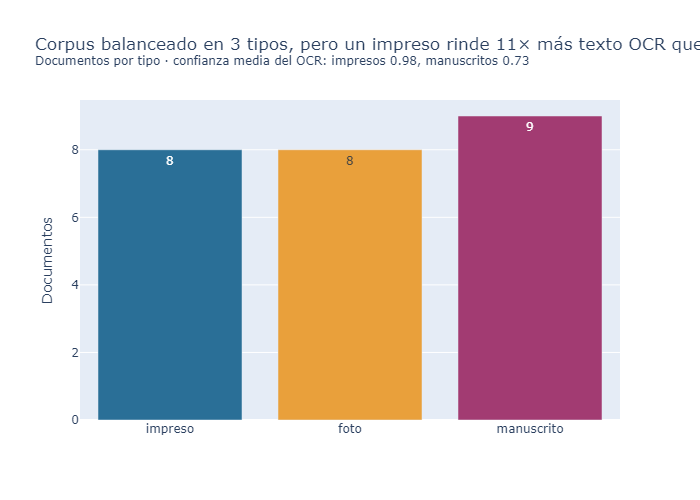

In [15]:
docs["n_caracteres"] = docs["texto_ocr"].str.len()
clips["n_palabras"] = clips["texto_asr"].map(lambda t: len(H.normalizar(t).split()))
por_tipo = docs.groupby("tipo").agg(documentos=("id", "size"), caracteres_medios=("n_caracteres", "mean"),
                                    confianza=("confianza_ocr", "mean")).reindex(["impreso", "foto", "manuscrito"]).reset_index()
imp, man = por_tipo.set_index("tipo").loc["impreso"], por_tipo.set_index("tipo").loc["manuscrito"]
fig = px.bar(por_tipo, x="tipo", y="documentos", color="tipo", text="documentos",
             hover_data={"caracteres_medios": ":.0f", "confianza": ":.2f"},
             color_discrete_map={"impreso": "#2a6f97", "foto": "#e9a03b", "manuscrito": "#a23b72"},
             title=(f"Corpus balanceado en 3 tipos, pero un impreso rinde {imp.caracteres_medios / man.caracteres_medios:.0f}× más texto OCR "
                    f"que un manuscrito<br><sup>Documentos por tipo · confianza media del OCR: impresos {imp.confianza:.2f}, "
                    f"manuscritos {man.confianza:.2f}</sup>"))
fig.update_layout(showlegend=False, yaxis_title="Documentos", xaxis_title="")
fig.show()

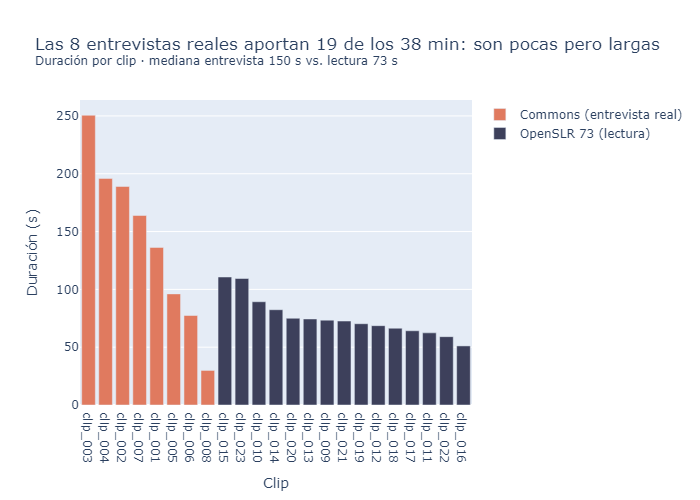

In [16]:
clips["origen"] = np.where(clips["fuente"] == "OpenSLR 73", "OpenSLR 73 (lectura)", "Commons (entrevista real)")
min_por_fuente = clips.groupby("origen")["duracion_seg"].sum() / 60
ent = clips[clips["origen"] == "Commons (entrevista real)"]
fig = px.bar(clips.sort_values("duracion_seg", ascending=False), x="id", y="duracion_seg", color="origen",
             hover_data=["descripcion", "n_hablantes"], color_discrete_sequence=["#e07a5f", "#3d405b"],
             title=(f"Las {len(ent)} entrevistas reales aportan {min_por_fuente['Commons (entrevista real)']:.0f} de los "
                    f"{clips['duracion_seg'].sum() / 60:.0f} min: son pocas pero largas<br><sup>Duración por clip · "
                    f"mediana entrevista {ent['duracion_seg'].median():.0f} s vs. lectura "
                    f"{clips.loc[clips['origen'] != 'Commons (entrevista real)', 'duracion_seg'].median():.0f} s</sup>"))
fig.update_layout(xaxis_title="Clip", yaxis_title="Duración (s)", legend_title="")
fig.show()

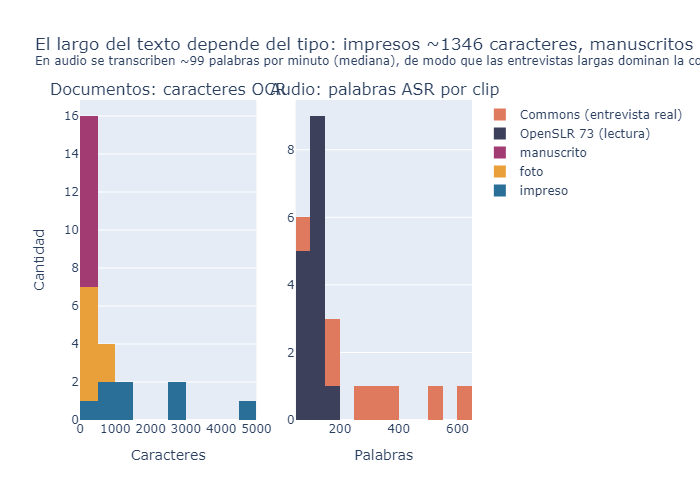

In [17]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go
ppm = (clips["n_palabras"] / (clips["duracion_seg"] / 60))
fig = make_subplots(rows=1, cols=2, subplot_titles=("Documentos: caracteres OCR", "Audio: palabras ASR por clip"))
for tipo, color in [("impreso", "#2a6f97"), ("foto", "#e9a03b"), ("manuscrito", "#a23b72")]:
    fig.add_trace(go.Histogram(x=docs.loc[docs["tipo"] == tipo, "n_caracteres"], name=tipo, marker_color=color, nbinsx=12), 1, 1)
for o, color in [("OpenSLR 73 (lectura)", "#3d405b"), ("Commons (entrevista real)", "#e07a5f")]:
    fig.add_trace(go.Histogram(x=clips.loc[clips["origen"] == o, "n_palabras"], name=o, marker_color=color, nbinsx=12), 1, 2)
fig.update_layout(barmode="stack", title=(
    f"El largo del texto depende del tipo: impresos ~{docs.loc[docs['tipo'] == 'impreso', 'n_caracteres'].median():.0f} caracteres, "
    f"manuscritos ~{docs.loc[docs['tipo'] == 'manuscrito', 'n_caracteres'].median():.0f}<br><sup>En audio se transcriben "
    f"~{ppm.median():.0f} palabras por minuto (mediana), de modo que las entrevistas largas dominan la cola derecha</sup>"))
fig.update_xaxes(title_text="Caracteres", row=1, col=1)
fig.update_xaxes(title_text="Palabras", row=1, col=2)
fig.update_yaxes(title_text="Cantidad", row=1, col=1)
fig.show()

## 7. Validación: extremos de longitud
Los 3 documentos con OCR más largo y más corto, y los 3 clips más largos y más cortos, para verificar que coinciden con los histogramas.

In [18]:
cols = ["id", "tipo", "descripcion", "n_caracteres", "confianza_ocr"]
d = docs.sort_values("n_caracteres")
print("OCR más largos:")
display(d.tail(3)[cols + ["texto_ocr"]].assign(texto_ocr=lambda x: x["texto_ocr"].str[:120]))
print("OCR más cortos:")
display(d.head(3)[cols + ["texto_ocr"]])

OCR más largos:


,id,tipo,descripcion,n_caracteres,confianza_ocr,texto_ocr
1,doc_002,impreso,"Ricardo Palma, «D. Dimas de la Tijereta» (p. 31)",2567,0.985714,"RICARDO PALMA\n31\ncomo si no hubiera estado en nanos de Adán, que era á la poștre un po-\nbrete educado m..."
3,doc_004,impreso,"Ricardo Palma, Tradiciones peruanas (p. 371)",2650,0.991978,RICARDO PALMA\n371\ndico una plaza en el regimiento de Mallorca. El manccbo asió la ocasión\npor el único ...
7,doc_008,impreso,"Decreto Ley 17716 de Reforma Agraria (1969), arts. 2-3",4894,0.990801,"Ia Rural efectiva, la asistencia técnica gene-\nexcluye el aprovechamiento directo de los bos-\nralizada, ..."


OCR más cortos:


,id,tipo,descripcion,n_caracteres,confianza_ocr,texto_ocr
19,doc_020,manuscrito,"Guaman Poma (1615), la villa del Callao",48,0.698305,1041\n1033\nCIVDAD\nLADECALL\n2\n口\n务\n爱\n\n2\nui lla\negta
8,doc_009,foto,"Placa a José Santos Chocano (1927), Lima",59,0.833530,J\nJOSE\nLASOCIEDAL DE BELLASARTES\nDIA DELA RAZA 1927\nLAGURTO
17,doc_018,manuscrito,"Guaman Poma (1615), el chasqui",66,0.941243,COREOMMAIORIMELIOR\nHATVAICHASOVICHVRV\nMVLLO·CHÁSQVI·CVRACA\ncove\non


In [19]:
cols = ["id", "origen", "duracion_seg", "n_palabras", "n_hablantes"]
c = clips.sort_values("duracion_seg")
print("Clips más largos:")
display(c.tail(3)[cols + ["texto_asr"]].assign(texto_asr=lambda x: x["texto_asr"].str[:120]))
print("Clips más cortos:")
display(c.head(3)[cols + ["texto_asr"]].assign(texto_asr=lambda x: x["texto_asr"].str[:120]))

Clips más largos:


,id,origen,duracion_seg,n_palabras,n_hablantes,texto_asr
1,clip_002,Commons (entrevista real),189.0,373,3,"[HABLANTE_1] Buenos días profesor y compañeros, hoy estoy cerca de aquí por mi casa y voy a hacer una entr..."
3,clip_004,Commons (entrevista real),196.0,521,2,"[HABLANTE_1] A ver, a ver, ¿cuál es la pregunta? [HABLANTE_2] Buenas noches, primeramente. Mi nombre es [P..."
2,clip_003,Commons (entrevista real),250.6,642,2,[HABLANTE_1] bueno ahora estamos en los san martín entre fiestas patrias de julio entonces primero podría ...


Clips más cortos:


,id,origen,duracion_seg,n_palabras,n_hablantes,texto_asr
7,clip_008,Commons (entrevista real),29.9,58,2,[HABLANTE_1] normal esperando el resultado pero como lo ves como ves a perú ahorita que está [HABLANTE_2] ...
15,clip_016,OpenSLR 73 (lectura),51.1,92,1,"¿Qué tal Alex, cómo están los niños? El Llano en Llamas es un clásico de Juan Rulfo ¿Qué dice titular del ..."
21,clip_022,OpenSLR 73 (lectura),59.1,127,2,[HABLANTE_1] ¿Ve usted la pestaña en la parte superior izquierda que dice buscar? Quiero deshacerme de alg...


Los extremos coinciden con los histogramas: los OCR más largos son páginas impresas de Palma y Garcilaso y los más cortos son manuscritos de Guaman Poma (casi todo dibujo, con un título y unas pocas palabras) o placas con poco texto. En audio, las entrevistas de Commons son las más largas y el clip de medio tiempo (30 s) el más corto; los clips de lectura tienen una duración muy pareja (~1 min) por construcción.

## 8. Ejemplos publicables para el dashboard
Solo se copian a `datos/ejemplos/` (versionado) archivos con licencia libre **y sin datos personales**:
* Imágenes de documentos de dominio público o CC BY/CC BY-SA cuya imagen no muestre nombres de personas privadas (se excluyen las placas que nombran a personas vivas), reducidas a 900 px.
* Audios de OpenSLR 73 (voluntarios anónimos que leen frases; CC BY-SA 4.0), comprimidos en OGG.
* Las entrevistas de Commons **no** se copian: aunque su licencia lo permite, las personas dicen sus nombres en el audio y eso no se puede seudonimizar. En el dashboard se consultan como texto seudonimizado y metadatos, con enlace a la ficha de la fuente.

In [20]:
ej = BASE / "datos" / "ejemplos"
(ej / "documentos").mkdir(parents=True, exist_ok=True)
(ej / "audio").mkdir(parents=True, exist_ok=True)
# Revisión visual: estas fotos muestran nombres de personas contemporáneas (aunque el OCR los lea mal)
IMAGENES_CON_NOMBRES = ["doc_010", "doc_013", "doc_015"]
docs["imagen_publicable"] = (docs["entidades_seudonimizadas"] == 0) & ~docs["id"].isin(IMAGENES_CON_NOMBRES)
from PIL import Image
for r in docs[docs["imagen_publicable"]].itertuples():
    im = Image.open(BASE / r.archivo).convert("RGB")
    im.thumbnail((900, 900))
    im.save(ej / "documentos" / f"{r.id}.jpg", quality=80)
docs["imagen_ejemplo"] = np.where(docs["imagen_publicable"], "datos/ejemplos/documentos/" + docs["id"] + ".jpg", "")
clips["audio_publicable"] = clips["fuente"] == "OpenSLR 73"
for r in clips[clips["audio_publicable"]].itertuples():
    x, sr = sf.read(BASE / r.archivo_audio, dtype="float32")
    # en Windows, libsndfile se desborda si se le pasa todo el audio de una vez a Vorbis: se escribe por bloques
    with sf.SoundFile(ej / "audio" / f"{r.id}.ogg", "w", sr, 1, format="OGG", subtype="VORBIS") as f:
        for i in range(0, len(x), 16_000):
            f.write(x[i:i + 16_000])
clips["audio_ejemplo"] = np.where(clips["audio_publicable"], "datos/ejemplos/audio/" + clips["id"] + ".ogg", "")
peso = sum(p.stat().st_size for p in ej.rglob("*") if p.is_file()) / 1e6
print(f"{docs['imagen_publicable'].sum()} imágenes y {clips['audio_publicable'].sum()} audios de ejemplo ({peso:.1f} MB)")

22 imágenes y 15 audios de ejemplo (7.7 MB)


## 9. Exportación
`texto_referencia` queda vacío en esta parte: se completa en la Parte 2 solo para la muestra de evaluación.

In [21]:
documentos = docs.assign(
    fuente=[f"{a[:60]} — {'Wikisource' if 'wikisource' in u else 'Wikimedia Commons'} ({l})"
            for a, u, l in zip(docs["autor"], docs["fuente_url"], docs["licencia"])],
    modelo_ocr="PaddleOCR 3.7.0 PP-OCRv6 medium det+rec (lang=es, sin preprocesamiento)",
    texto_referencia="",
)[["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia",
   "descripcion", "licencia", "fuente_url", "n_lineas_ocr", "confianza_ocr", "segundos_ocr", "n_caracteres",
   "entidades_seudonimizadas", "imagen_publicable", "imagen_ejemplo"]]
transcripciones = clips.assign(
    idioma="es (español peruano, declarado por la fuente; idioma fijado en el modelo)",
    modelo_asr="faster-whisper 1.2.1 large-v3-turbo (int8 CPU, VAD Silero on, beam 5) + diarización WeSpeaker",
    texto_referencia="",
)[["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr", "n_hablantes", "texto_referencia",
   "fuente", "origen", "descripcion", "licencia", "fuente_url", "fraccion_voz", "segundos_asr", "rtf", "n_palabras",
   "entidades_seudonimizadas", "audio_publicable", "audio_ejemplo"]]
fuentes = inv[inv["id"].isin(documentos["id"]) | inv["id"].isin(transcripciones["id"])][
    ["id", "modalidad", "fuente_url", "licencia", "acceso", "autor", "titulo_original", "fecha_extraccion"]]
documentos.to_csv(BASE / "datos" / "documentos.csv", index=False)
transcripciones.to_csv(BASE / "datos" / "transcripciones.csv", index=False)
fuentes.to_csv(BASE / "datos" / "fuentes.csv", index=False)
print("documentos.csv", documentos.shape, "| transcripciones.csv", transcripciones.shape, "| fuentes.csv", fuentes.shape)
print(f"Audio total: {transcripciones['duracion_seg'].sum() / 60:.1f} min en {len(transcripciones)} clips; "
      f"clips con 2+ hablantes detectados: {(transcripciones['n_hablantes'] >= 2).sum()}")
documentos.head(5)

documentos.csv (25, 17) | transcripciones.csv (23, 20) | fuentes.csv (48, 8)
Audio total: 37.8 min en 23 clips; clips con 2+ hablantes detectados: 9


,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia,descripcion,licencia,fuente_url,n_lineas_ocr,confianza_ocr,segundos_ocr,n_caracteres,entidades_seudonimizadas,imagen_publicable,imagen_ejemplo
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,Ricardo Palma — Wikisource (Dominio público (texto y escaneo)),D. DIMAS DE LA TIJERETA\nCUENTO DE VIEJAS QUE TRATA DE CÓMO UN ESCRIBANO LE GANÓ UN PLEITO AL DIABLO\nI\nÉ...,"PaddleOCR 3.7.0 PP-OCRv6 medium det+rec (lang=es, sin preprocesamiento)",,"Ricardo Palma, «D. Dimas de la Tijereta» (inicio)",Dominio público (texto y escaneo),https://es.wikisource.org/wiki/P%C3%A1gina%3ATradiciones_peruanas_-_Tomo_I_%281893%29.pdf/35,25,0.990363,32.727,1414,0,True,datos/ejemplos/documentos/doc_001.jpg
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,Ricardo Palma — Wikisource (Dominio público (texto y escaneo)),"RICARDO PALMA\n31\ncomo si no hubiera estado en nanos de Adán, que era á la poștre un po-\nbrete educado m...","PaddleOCR 3.7.0 PP-OCRv6 medium det+rec (lang=es, sin preprocesamiento)",,"Ricardo Palma, «D. Dimas de la Tijereta» (p. 31)",Dominio público (texto y escaneo),https://es.wikisource.org/wiki/P%C3%A1gina%3ATradiciones_peruanas_-_Tomo_I_%281893%29.pdf/37,42,0.985714,57.645,2567,0,True,datos/ejemplos/documentos/doc_002.jpg
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,Ricardo Palma — Wikisource (Dominio público (texto y escaneo)),LOS MALDITOS\nCRÓNICA DE LA ÉPOCA DEL NOVENO VIRREY DEL PERÚ\nI\nSAN PEDRO·MAMA\nPor los años de 1601 exis...,"PaddleOCR 3.7.0 PP-OCRv6 medium det+rec (lang=es, sin preprocesamiento)",,"Ricardo Palma, «Los malditos» (inicio)",Dominio público (texto y escaneo),https://es.wikisource.org/wiki/P%C3%A1gina%3ATradiciones_peruanas_-_Tomo_I_%281893%29.pdf/187,22,0.978736,34.202,1277,0,True,datos/ejemplos/documentos/doc_003.jpg
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,Ricardo Palma — Wikisource (Dominio público (texto y escaneo)),RICARDO PALMA\n371\ndico una plaza en el regimiento de Mallorca. El manccbo asió la ocasión\npor el único ...,"PaddleOCR 3.7.0 PP-OCRv6 medium det+rec (lang=es, sin preprocesamiento)",,"Ricardo Palma, Tradiciones peruanas (p. 371)",Dominio público (texto y escaneo),https://es.wikisource.org/wiki/P%C3%A1gina%3ATradiciones_peruanas_-_Tomo_I_%281893%29.pdf/377,43,0.991978,52.577,2650,0,True,datos/ejemplos/documentos/doc_004.jpg
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,Inca Garcilaso de la Vega — Wikisource (Dominio público (texto y escaneo)),\nHISTORIA\nGENERAL\nPERU.\nDEI\nCAPÍTULO PRIMERO.\nSi bay mucbos mundos. Trátase de\nlas cinco xonas.\nvo...,"PaddleOCR 3.7.0 PP-OCRv6 medium det+rec (lang=es, sin preprocesamiento)",,"Inca Garcilaso, Historia General del Perú, cap. I",Dominio público (texto y escaneo),https://es.wikisource.org/wiki/P%C3%A1gina%3AHistoria_General_del_Per%C3%BA.djvu/41,18,0.922999,23.611,398,0,True,datos/ejemplos/documentos/doc_005.jpg


In [22]:
transcripciones.head(5)

,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia,fuente,origen,descripcion,licencia,fuente_url,fraccion_voz,segundos_asr,rtf,n_palabras,entidades_seudonimizadas,audio_publicable,audio_ejemplo
0,clip_001,datos/raw/audio/clip_001.wav,136.3,"es (español peruano, declarado por la fuente; idioma fijado en el modelo)","[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme su opinión acerca del...","faster-whisper 1.2.1 large-v3-turbo (int8 CPU, VAD Silero on, beam 5) + diarización WeSpeaker",2,,Wikimedia Commons,Commons (entrevista real),"Entrevista en la calle a una vendedora de frutas, El Agustino (2022)",CC BY-SA 4.0,https://commons.wikimedia.org/wiki/File:Entrevista_1_en_la_Av._Rivag%C3%BCero_-_El_Agustino.ogg,0.77,61.56,0.452,266,2,False,
1,clip_002,datos/raw/audio/clip_002.wav,189.0,"es (español peruano, declarado por la fuente; idioma fijado en el modelo)","[HABLANTE_1] Buenos días profesor y compañeros, hoy estoy cerca de aquí por mi casa y voy a hacer una entr...","faster-whisper 1.2.1 large-v3-turbo (int8 CPU, VAD Silero on, beam 5) + diarización WeSpeaker",3,,Wikimedia Commons,Commons (entrevista real),"Entrevista en la calle a dos vendedoras de dulces, El Agustino (2022)",CC BY-SA 4.0,https://commons.wikimedia.org/wiki/File:Entrevista_2_en_la_Av._Rivag%C3%BCero_-_El_Agustino.ogg,0.83,85.35,0.452,373,10,False,
2,clip_003,datos/raw/audio/clip_003.wav,250.6,"es (español peruano, declarado por la fuente; idioma fijado en el modelo)",[HABLANTE_1] bueno ahora estamos en los san martín entre fiestas patrias de julio entonces primero podría ...,"faster-whisper 1.2.1 large-v3-turbo (int8 CPU, VAD Silero on, beam 5) + diarización WeSpeaker",2,,Wikimedia Commons,Commons (entrevista real),Dirigente de una organización de mujeres indígenas en conferencia de prensa (2022),CC BY-SA 4.0,https://commons.wikimedia.org/?curid=121219890,0.96,137.67,0.549,642,1,False,
3,clip_004,datos/raw/audio/clip_004.wav,196.0,"es (español peruano, declarado por la fuente; idioma fijado en el modelo)","[HABLANTE_1] A ver, a ver, ¿cuál es la pregunta? [HABLANTE_2] Buenas noches, primeramente. Mi nombre es [P...","faster-whisper 1.2.1 large-v3-turbo (int8 CPU, VAD Silero on, beam 5) + diarización WeSpeaker",2,,Wikimedia Commons,Commons (entrevista real),Entrevista de un estudiante de la UNMSM por Fiestas Patrias (2022),CC BY-SA 4.0,"https://commons.wikimedia.org/wiki/File:Entrevista_1,.wav",0.90,113.61,0.580,521,4,False,
4,clip_005,datos/raw/audio/clip_005.wav,96.1,"es (español peruano, declarado por la fuente; idioma fijado en el modelo)","Nos encontramos aquí con el señor [PERSONA_07], señor [PERSONA_07], esta entrevista va a ser subida a inte...","faster-whisper 1.2.1 large-v3-turbo (int8 CPU, VAD Silero on, beam 5) + diarización WeSpeaker",1,,Wikimedia Commons,Commons (entrevista real),Entrevista de un estudiante de la UNMSM por Fiestas Patrias (2022),CC BY-SA 4.0,https://commons.wikimedia.org/wiki/File:Entrevista_2.wav,0.85,33.48,0.348,182,2,False,


In [23]:
fuentes.head(5)

,id,modalidad,fuente_url,licencia,acceso,autor,titulo_original,fecha_extraccion
0,doc_001,documento,https://es.wikisource.org/wiki/P%C3%A1gina%3ATradiciones_peruanas_-_Tomo_I_%281893%29.pdf/35,Dominio público (texto y escaneo),descargar_datos.py: API de Wikimedia (imageinfo) y guardar como JPEG de 2400 px máx.,Ricardo Palma,Tradiciones peruanas - Tomo I (1893).pdf (página 35),2026-10-25
1,doc_002,documento,https://es.wikisource.org/wiki/P%C3%A1gina%3ATradiciones_peruanas_-_Tomo_I_%281893%29.pdf/37,Dominio público (texto y escaneo),descargar_datos.py: API de Wikimedia (imageinfo) y guardar como JPEG de 2400 px máx.,Ricardo Palma,Tradiciones peruanas - Tomo I (1893).pdf (página 37),2026-10-25
2,doc_003,documento,https://es.wikisource.org/wiki/P%C3%A1gina%3ATradiciones_peruanas_-_Tomo_I_%281893%29.pdf/187,Dominio público (texto y escaneo),descargar_datos.py: API de Wikimedia (imageinfo) y guardar como JPEG de 2400 px máx.,Ricardo Palma,Tradiciones peruanas - Tomo I (1893).pdf (página 187),2026-10-25
3,doc_004,documento,https://es.wikisource.org/wiki/P%C3%A1gina%3ATradiciones_peruanas_-_Tomo_I_%281893%29.pdf/377,Dominio público (texto y escaneo),descargar_datos.py: API de Wikimedia (imageinfo) y guardar como JPEG de 2400 px máx.,Ricardo Palma,Tradiciones peruanas - Tomo I (1893).pdf (página 377),2026-10-25
4,doc_005,documento,https://es.wikisource.org/wiki/P%C3%A1gina%3AHistoria_General_del_Per%C3%BA.djvu/41,Dominio público (texto y escaneo),descargar_datos.py: API de Wikimedia (imageinfo) y guardar como JPEG de 2400 px máx.,Inca Garcilaso de la Vega,Historia General del Perú.djvu (página 41),2026-10-25
